# Teste de modelos em ligações reais (Nexus)

**Pergunta de negócio:** para cada KPI do speech analytics, qual modelo disponível no Nexus entrega o
resultado mais próximo da referência pelo menor custo e dentro do SLA de latência?

O notebook:

1. carrega as ligações do período na base de KPIs do Azure (conexão padrão `DefaultAzureCredential`,
   via `kpibench.data.azure_blob_loader`), com o resumo de cada ligação;
2. estima o custo do teste **antes** de chamar qualquer modelo;
3. gera a **referência** (modelo mais forte via Nexus, ou um arquivo com rótulos auditados);
4. roda os modelos candidatos via Nexus com o **mesmo prompt por KPI** e avalia com o pipeline do
   `kpibench` (métrica primária por KPI, IC por bootstrap pareado, não-inferioridade);
5. mostra o resultado em painéis executivos e permite inspecionar ligações individuais.

> **Como ler:** sem rótulos auditados, as métricas medem **concordância com a referência**, não acerto.
> A produção atual entra na comparação só nos KPIs em que o domínio é comparável (seção 7.6).

**Pré-requisitos:** `az login` feito; `.env` com `base_url` e `bearer_token` do Nexus;
`pip install -e ".[llm,azure]"`. Respostas ficam em cache (`.cache/llm_cache.sqlite`): reexecutar não gera custo.

In [1]:
import sys
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

try:
    from dotenv import load_dotenv
    load_dotenv(PROJECT_ROOT / ".env")
except ImportError:
    pass

from kpibench import live
from kpibench.reporting import aa_charts as charts

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
%matplotlib inline


def mostrar(fig):
    # exibe explicitamente: o pipeline troca o backend do matplotlib para Agg ao gerar o report.md
    if fig is not None:
        display(fig)
        plt.close(fig)

## 1. Parâmetros

Ajuste aqui e rode o notebook de cima para baixo. `NUM_CALLS` controla o tamanho (e o custo) do teste:
com poucas dezenas de ligações quase toda comparação entre modelos próximos sai **inconclusiva**; para
decidir, planeje algumas centenas.

In [23]:
# ---- Janela e volume de ligações -------------------------------------------------------------
START_DATE = "2026-09-01"   # "YYYY-MM-DD"; START_DATE = END_DATE = None -> última janela registrada na base
END_DATE   = "2026-10-28"
NUM_CALLS  = 25            # ligações a testar (mínimo 10, regra do azure_blob_loader)
CALL_IDS   = []             # opcional: restringe a ligações específicas da janela (ex.: casos de reclamação)

# ---- Modelos (todos via gateway Nexus; ids de config/models.yaml) --------------------------------
MODELOS = [
    "gpt-6-luna", "gpt-5-mini", "gpt-4.1", "gpt-4o-mini",
    "claude-haiku-5-5", "claude-sonnet-5-5",
    "deepseek-v4-flash", "grok-4.3", "kimi-k2.6",
]
USAR_TODOS_MODELOS_NEXUS = False  # True: ignora a lista acima e testa TODOS os modelos cadastrados em
                                   # config/models.yaml (menos REFERENCIA/JUIZ) — custo e tempo bem maiores
REFERENCIA = "claude-opus-5-5"   # modelo de referência via Nexus, ou "arquivo:<csv com call_id + gt_*>"
JUIZ = "gpt-6-luna"             # juiz dos KPIs de texto livre (razão do CSAT, solver reasoning)
KPIS = "all"                     # ou lista, ex.: ["csat", "razao_ligacao", "first_call_resolution"]

# ---- Leitura de negócio ----------------------------------------------------------------------
PESOS_KPI = {}                   # peso no índice geral, ex.: {"csat": 2.0, "odc": 1.5}; ausente = 1
SLA_LATENCIA_S = 5.0             # linha de SLA no gráfico de latência (segundos por chamada de KPI)
CASOS_PARA_INSPECIONAR = 3       # ligações com mais divergência exibidas lado a lado

# ---- Execução --------------------------------------------------------------------------------
EXECUTAR = True                  # False: para depois da estimativa de custo
METRICAS_RESUMO_LLM = False      # True: fidelidade por afirmações no resumo (1 chamada extra por ligação)
N_BOOTSTRAP = 1000
MAX_WORKERS = 8                  # chamadas simultâneas ao Nexus
MODO_SIMULADO = False            # True: sem Azure/Nexus (arquivo de exemplo + modelos simulados) para testar o fluxo

## 2. Conexão com o Nexus

In [24]:
cfg = live.build_config(models=MODELOS, kpis=KPIS, judge_model=JUIZ, simulated=MODO_SIMULADO,
                        n_bootstrap=N_BOOTSTRAP, max_workers=MAX_WORKERS,
                        llm_summary_metrics=METRICAS_RESUMO_LLM)

if USAR_TODOS_MODELOS_NEXUS:
    # todos os modelos do registro (config/models.yaml) servidos via Nexus, exceto a referência e o
    # juiz (que já são chamados à parte); a disponibilidade real no gateway é checada logo abaixo
    MODELOS = sorted(m for m, spec in cfg.model_registry.items()
                      if spec.provider == "nexus" and m not in (REFERENCIA, JUIZ))
    cfg.models = list(MODELOS)
    print(f"USAR_TODOS_MODELOS_NEXUS=True: testando todos os {len(MODELOS)} modelos do registro: {MODELOS}")

disponiveis = None if MODO_SIMULADO else live.nexus_models()
modelos_df = live.check_models(cfg, MODELOS + [REFERENCIA] if not REFERENCIA.startswith("arquivo:") else MODELOS,
                               disponiveis)
display(modelos_df.style.format({"preco_entrada_usd_1M": "US$ {:.3f}", "preco_saida_usd_1M": "US$ {:.3f}"})
        .hide(axis="index"))

if disponiveis is not None:
    fora = modelos_df.loc[~modelos_df["disponivel_no_nexus"].astype(bool), "modelo"].tolist()
    if fora:
        print(f"Fora do Nexus agora (removidos do teste): {fora}")
        MODELOS = [m for m in MODELOS if m not in fora]
        cfg.models = [m for m in cfg.models if m not in fora]
if modelos_df["preco_estimado"].any():
    print("Preço ESTIMADO (sem tabela oficial conferida):",
          ", ".join(modelos_df.loc[modelos_df["preco_estimado"], "modelo"]))

modelo,provedor,id_no_nexus,disponivel_no_nexus,preco_entrada_usd_1M,preco_saida_usd_1M,preco_estimado
gpt-6-luna,OpenAI,gpt-6-luna,True,US$ 0.100,US$ 0.500,False
gpt-5-mini,OpenAI,gpt-5-mini,True,US$ 0.250,US$ 2.000,False
gpt-4.1,OpenAI,gpt-4.1,True,US$ 2.000,US$ 8.000,False
gpt-4o-mini,OpenAI,gpt-4o-mini,True,US$ 0.150,US$ 0.600,False
claude-haiku-5-5,Anthropic,claude-haiku-5-5,True,US$ 0.100,US$ 0.500,False
claude-sonnet-5-5,Anthropic,claude-sonnet-5-5,True,US$ 2.000,US$ 10.000,False
deepseek-v4-flash,DeepSeek,deepseek-v4-flash,True,US$ 0.140,US$ 0.280,True
grok-4.3,xAI,grok-4.3,True,US$ 1.250,US$ 2.500,True
kimi-k2.6,Moonshot,kimi-k2.6,True,US$ 0.950,US$ 4.000,True
claude-opus-5-5,Anthropic,claude-opus-5-5,True,US$ 4.000,US$ 20.000,False


Preço ESTIMADO (sem tabela oficial conferida): deepseek-v4-flash, grok-4.3, kimi-k2.6


**Sobre a coluna `disponivel_no_nexus`:** `config/models.yaml` é um cadastro estático (preço, limites
de parâmetros etc.); o catálogo real do gateway (`GET /models`) muda com o tempo — um modelo pode ser
descontinuado ou renomeado no Nexus sem que o cadastro seja atualizado. Quando essa coluna aparece como
`False` (ou impressa como "Fora do Nexus agora"), o modelo **não está sendo testado nesta rodada**: ele é
removido automaticamente de `MODELOS` antes da estimativa de custo e da execução, para não gastar tempo
tentando chamar um endpoint inexistente. Isso é diferente de um modelo que roda mas responde mal (ver a
coluna `Respostas válidas` no placar, seção 7.7) — aqui o modelo simplesmente não está acessível.

## 3. Ligações da base de KPIs (Azure, conexão padrão)

`load_calls` reaproveita o `azure_blob_loader` (mesma conta, container e prefixo) e completa cada
ligação com o **texto do resumo** — que é a entrada dos prompts — e, quando houver, da transcrição.

[azure_blob_loader] Chamadas usadas na análise: 25
[azure_calls] 25 ligações · com resumo: 25 · com transcrição: 25
Ligações carregadas: 25 · com resumo utilizável: 25 · período: 15/09/2026 a 18/09/2026


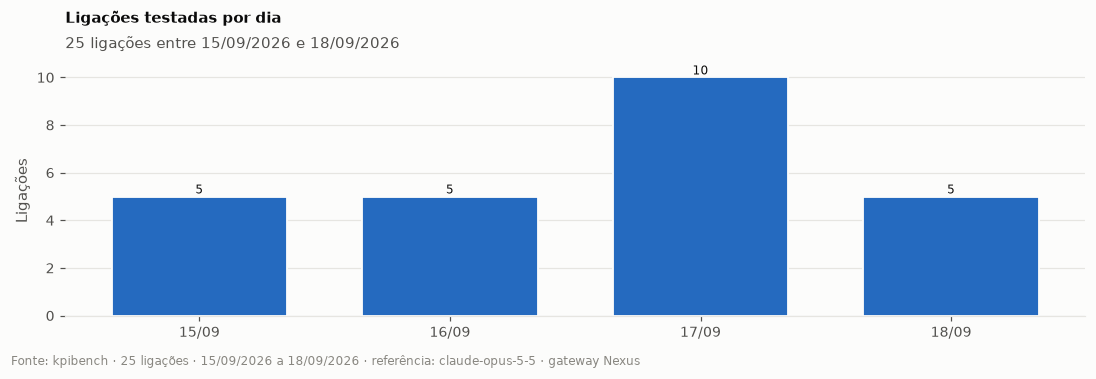

,call_id,data_referencia,origem_resumo,resumo
0,2b5d8efa-80b9-4b7e-b143-fb748bf94010,2026-09-15,url:summary,"A chamada foi realizada por Mayara, atendente da Brasil CAP, para Edide Azevedo da Cunha. Edide solicitou informaçõe..."
1,341fde30-df0e-4b8e-afee-7a992dac38ad,2026-09-15,url:summary,"A chamada foi realizada por Gilberto Ferreira da Silva, que estava tentando resgatar um valor de R$ 150 do Banco do ..."
2,86656231-6846-4072-a1ea-39554417d259,2026-09-15,url:summary,"A chamada foi realizada por João, que entrou em contato com a central de atendimento e falou com Valéria. Ele solici..."
3,8a2f014c-3a59-4b41-af3e-a595ba8d700b,2026-09-15,url:summary,"A chamada foi realizada por Priscila, uma atendente, para João Vladimir. O objetivo era verificar informações sobre ..."
4,a6c0a3d6-ff1f-4c48-aee8-38a2ab827381,2026-09-15,url:summary,"O cliente, Jair Solarecimento, entrou em contato com a Brasil Carpe para obter informações sobre o crédito de um pla..."


In [25]:
if MODO_SIMULADO:
    calls = live.sample_calls(NUM_CALLS)
    PERIODO = "arquivo de exemplo (simulado)"
else:
    from kpibench.data.azure_calls import load_calls
    calls = load_calls(START_DATE, END_DATE, NUM_CALLS, call_ids=CALL_IDS or None, max_workers=MAX_WORKERS)
    PERIODO = (f"{pd.to_datetime(calls['data_referencia']).min():%d/%m/%Y} a "
               f"{pd.to_datetime(calls['data_referencia']).max():%d/%m/%Y}") if len(calls) else "—"

com_resumo = calls["resumo"].fillna("").str.len().ge(20) if len(calls) else pd.Series(dtype=bool)
print(f"Ligações carregadas: {len(calls)} · com resumo utilizável: {int(com_resumo.sum())} · período: {PERIODO}")
FOOTER = (f"Fonte: kpibench · {int(com_resumo.sum())} ligações · {PERIODO} · referência: {REFERENCIA} · "
          f"gateway Nexus{' · SIMULADO' if MODO_SIMULADO else ''}")

mostrar(charts.calls_per_day(calls, FOOTER))
display(calls.loc[:, [c for c in ["call_id", "data_referencia", "origem_resumo", "resumo"] if c in calls]].head(5))

**Se o resumo vier vazio:** a estrutura do JSON de resumo não está documentada no repositório e a
extração usa heurísticas. A célula abaixo mostra o esqueleto de um blob real para ajustar
`SUMMARY_KEYS` em `kpibench/data/azure_calls.py` (ou passar `summary_keys=` para `load_calls`).

In [26]:
if not MODO_SIMULADO and len(calls) and (~com_resumo).any():
    from kpibench.data.azure_calls import inspect_blob_structure
    exemplo = calls.loc[~com_resumo].iloc[0]
    alvo = exemplo.get("summary") if str(exemplo.get("summary", "")).startswith("http") else exemplo["blob_name"]
    print(f"Estrutura de: {alvo}\n")
    inspect_blob_structure(alvo)
else:
    print("Todas as ligações têm resumo utilizável — nada a inspecionar.")

Todas as ligações têm resumo utilizável — nada a inspecionar.


## 4. Custo estimado do teste (antes de executar)

Tokens de entrada medidos nos prompts reais destas ligações; saída assumida por tipo de KPI
(+300 tokens de raciocínio nos modelos com `reasoning_effort`). O custo **medido** aparece depois da execução.

In [27]:
ref_model = None if REFERENCIA.startswith("arquivo:") else REFERENCIA
estimativa = live.estimate_cost(cfg, calls[com_resumo], ref_model)
display(estimativa.style.format({"usd_estimado": charts.usd}).hide(axis="index"))
if not EXECUTAR:
    raise SystemExit("EXECUTAR = False: revise a estimativa e mude o parâmetro para rodar o teste.")

modelo,papel,chamadas_llm,usd_estimado,preco_estimado
gpt-6-luna,candidato,275,"US$ 0,073",False
gpt-5-mini,candidato,275,"US$ 0,26",False
gpt-4.1,candidato,275,"US$ 0,58",False
gpt-4o-mini,candidato,275,"US$ 0,044",False
claude-haiku-5-5,candidato,275,"US$ 0,031",False
claude-sonnet-5-5,candidato,275,"US$ 0,63",False
deepseek-v4-flash,candidato,275,"US$ 0,035",True
grok-4.3,candidato,275,"US$ 0,31",True
kimi-k2.6,candidato,275,"US$ 0,28",True
claude-opus-5-5,referência,275,"US$ 1,26",False


## 5. Execução (referência + candidatos via Nexus)

In [7]:
resultado = live.run_live(cfg, calls[com_resumo], REFERENCIA)
res = live.load_results(resultado.run_dir)
placar = live.model_scoreboard(res, cfg, PESOS_KPI)
N = len(resultado.dataset)
print(f"Resultados em: {resultado.run_dir}")
print(f"Custo da referência: {charts.usd(resultado.reference_cost_usd)}")

Referência: claude-opus-5-5 em 25 ligações × 11 KPIs
Extração: 275 chamadas (1 modelos x 11 KPIs x 25 registros)
  [extração] 27/275
  [extração] 54/275
  [extração] 81/275
  [extração] 108/275
  [extração] 135/275
  [extração] 162/275
  [extração] 189/275
  [extração] 216/275
  [extração] 243/275
  [extração] 270/275
  [extração] 275/275
Referência com saídas inválidas (ligações ignoradas nesses KPIs):
kpi
qualidade_resumo    4.0%
[aviso] KPI 'qualidade_resumo': 1 rótulos ausentes/fora do domínio (linhas ignoradas nesse KPI)
Extração: 2475 chamadas (9 modelos x 11 KPIs x 25 registros)
  [extração] 247/2475
  [extração] 494/2475
  [extração] 741/2475
  [extração] 988/2475
  [extração] 1235/2475
  [extração] 1482/2475
  [extração] 1729/2475
  [extração] 1976/2475
  [extração] 2223/2475
  [extração] 2470/2475
  [extração] 2475/2475
Juiz (gpt-6-luna): 656 chamadas
  [juiz] 65/656
  [juiz] 130/656
  [juiz] 195/656
  [juiz] 260/656
  [juiz] 325/656
  [juiz] 390/656
  [juiz] 455/656
  [juiz]

Resultados em: /home/ab1344549/PSO/DataOcean.MLPSO/llm_bench/rev2/kpillmbenchmark/outputs/teste_ligacoes_20261111_160256/benchmark_20261111_160345
Custo da referência: US$ 2,85



Relatório: /home/ab1344549/PSO/DataOcean.MLPSO/llm_bench/rev2/kpillmbenchmark/outputs/teste_ligacoes_20261111_160256/benchmark_20261111_160345/report.md


## 6. Resumo executivo

**25 ligações · 15/09/2026 a 18/09/2026 · referência: `claude-opus-5-5`** (métricas = concordância com a referência).

- **Maior concordância:** `claude-sonnet-5-5`, índice 79,0/100, US$ 44,16 por 1.000 ligações (todos os KPIs selecionados).
- **Nenhum modelo é não-inferior ao melhor em todos os KPIs** com esta amostra: o roteamento por KPI é o caminho.
- **Melhor índice por dólar:** `deepseek-v4-flash` (63,7 pontos a US$ 1,16/1.000 ligações).
- **Roteamento recomendado por KPI:** US$ 36,24 por 1.000 ligações (cada KPI no modelo mais barato não-inferior; ver tabela 7.7).
- **Latência:** p95 de 2,6 s a 15,4 s por chamada de KPI (mais lento: `grok-4.3`).
- **Custo estimado** (sem tabela oficial) para: `claude-sonnet-5-5`, `gpt-6-luna`, `deepseek-v4-flash`, `grok-4.3`, `claude-haiku-5-5`, `kimi-k2.6`.
- **49 comparações inconclusivas:** a amostra não separa modelos próximos; aumente `NUM_CALLS` antes de decidir.

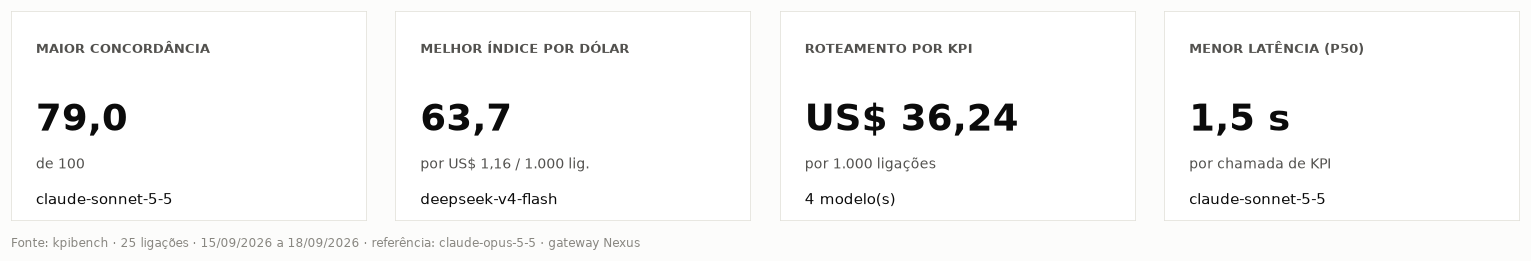

In [8]:
display(Markdown(live.executive_summary(placar, res, resultado, N, PERIODO)))
mostrar(charts.scorecards(placar, res.routing, N, FOOTER))

## 7. Painéis

### 7.1 Ranking geral
Média da métrica primária dos KPIs selecionados (com `PESOS_KPI`, se definidos), em escala 0–100.

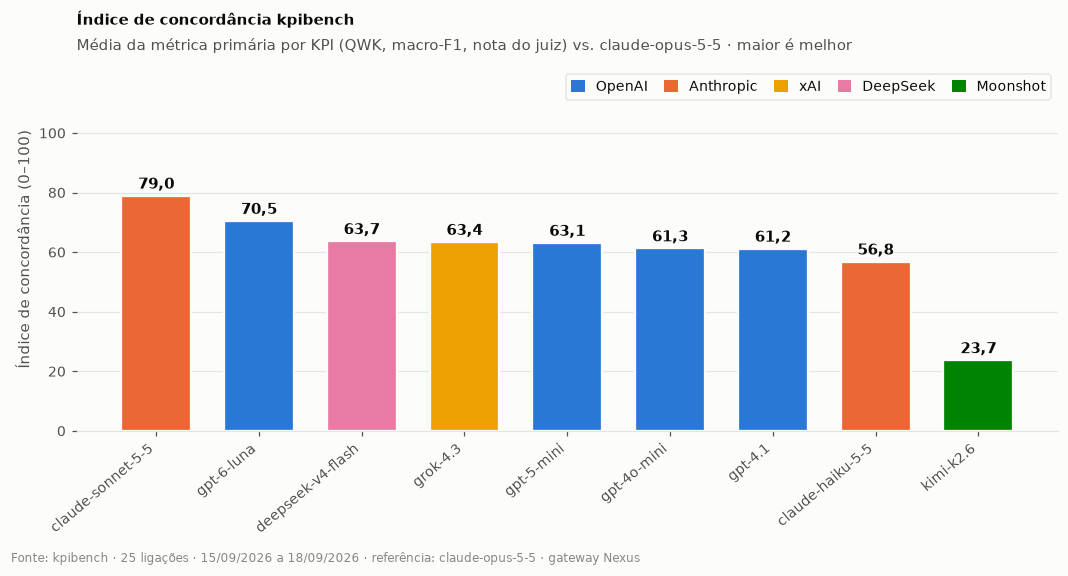

In [9]:
mostrar(charts.leaderboard(placar, FOOTER, REFERENCIA))

### 7.2 Concordância × custo
O quadrante verde reúne quem está acima da concordância mediana **e** abaixo do custo mediano.
Ponto vazado = preço estimado.

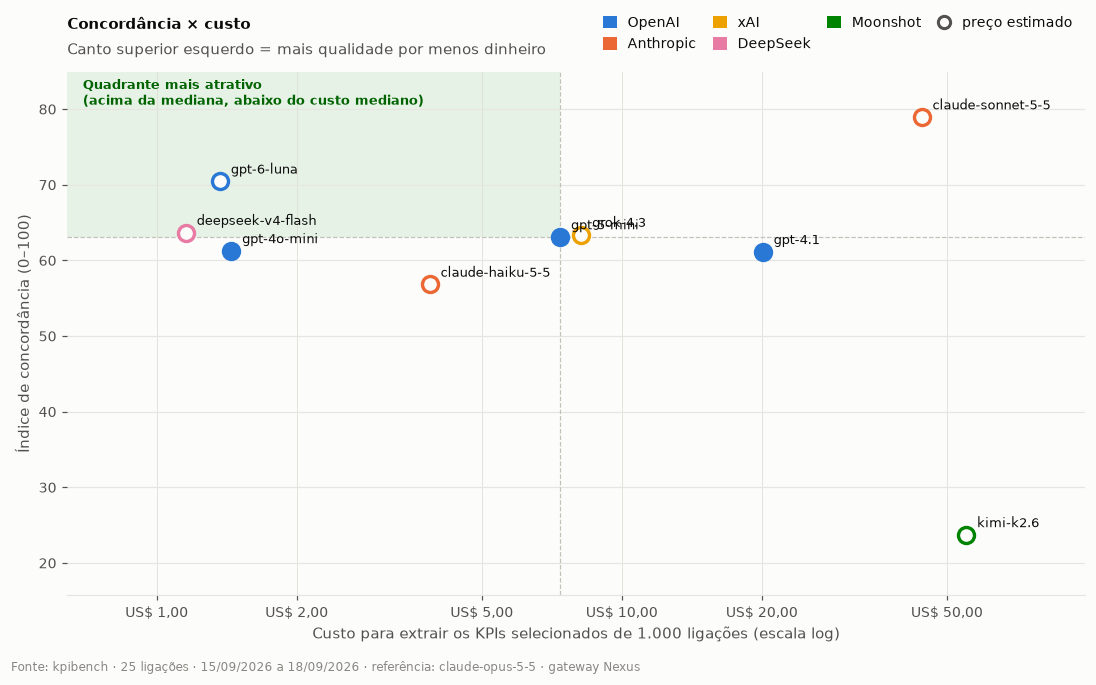

In [19]:
mostrar(charts.quality_vs_cost(placar, FOOTER))

### 7.3 Custo por 1.000 ligações

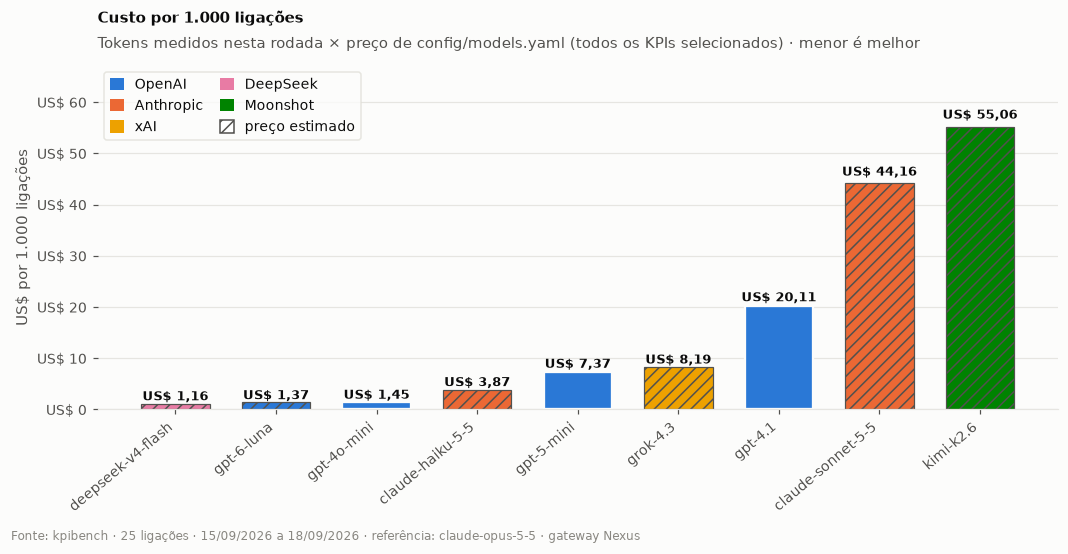

In [11]:
mostrar(charts.cost_bars(placar, FOOTER))

### 7.4 Latência e confiabilidade

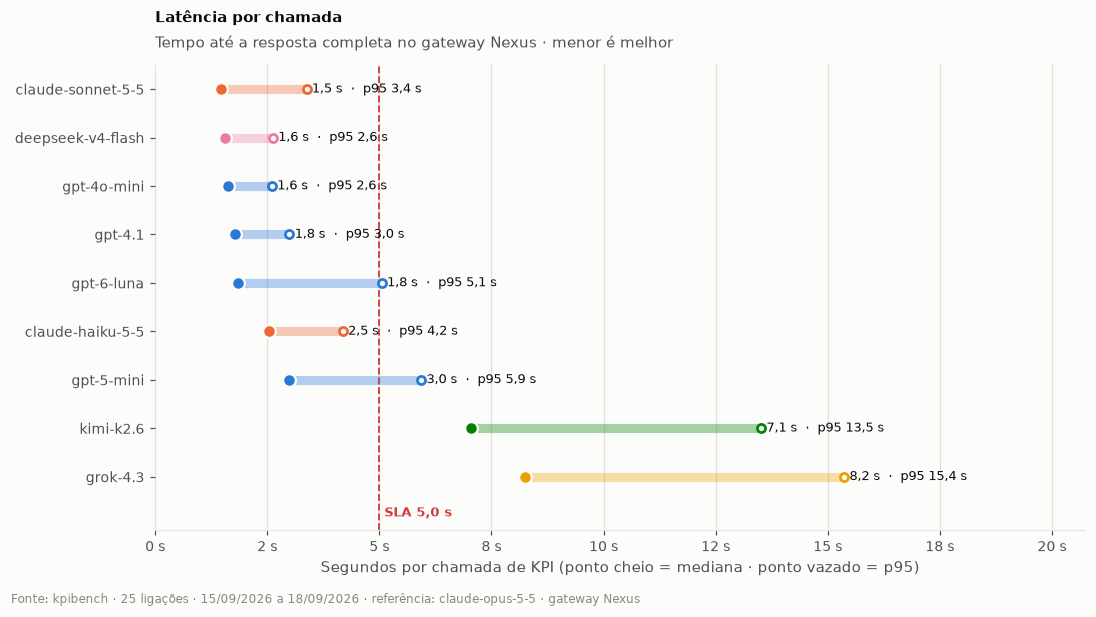

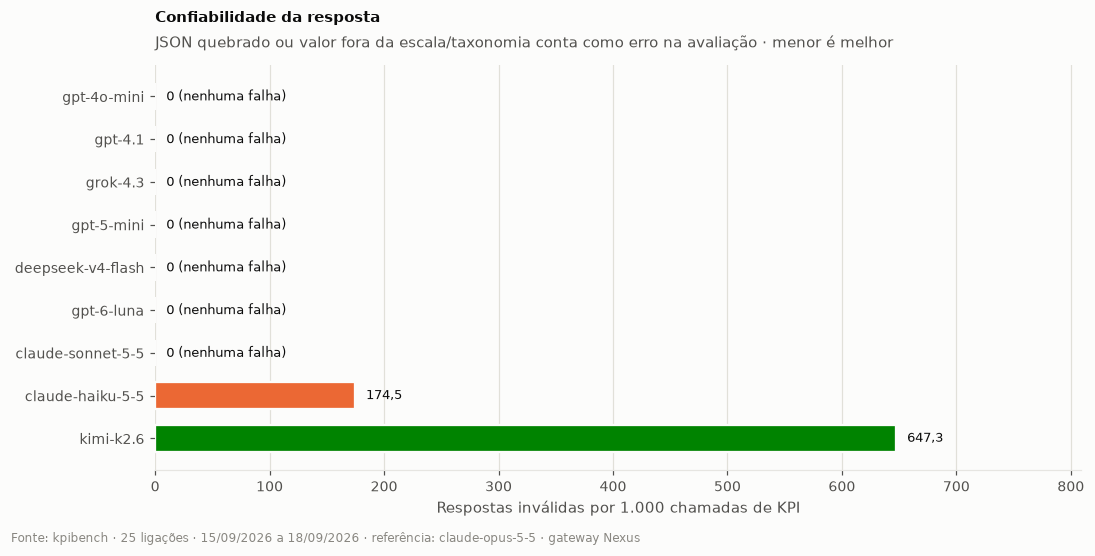

In [12]:
mostrar(charts.latency_chart(placar, FOOTER, sla_s=SLA_LATENCIA_S))
mostrar(charts.reliability_bars(placar, FOOTER))

### 7.5 Concordância por KPI
O heatmap dá a visão geral; os painéis seguintes mostram a incerteza (IC 95%). Um modelo só é
recomendado se for **não-inferior** ao melhor — se os ICs se sobrepõem muito, falta amostra.

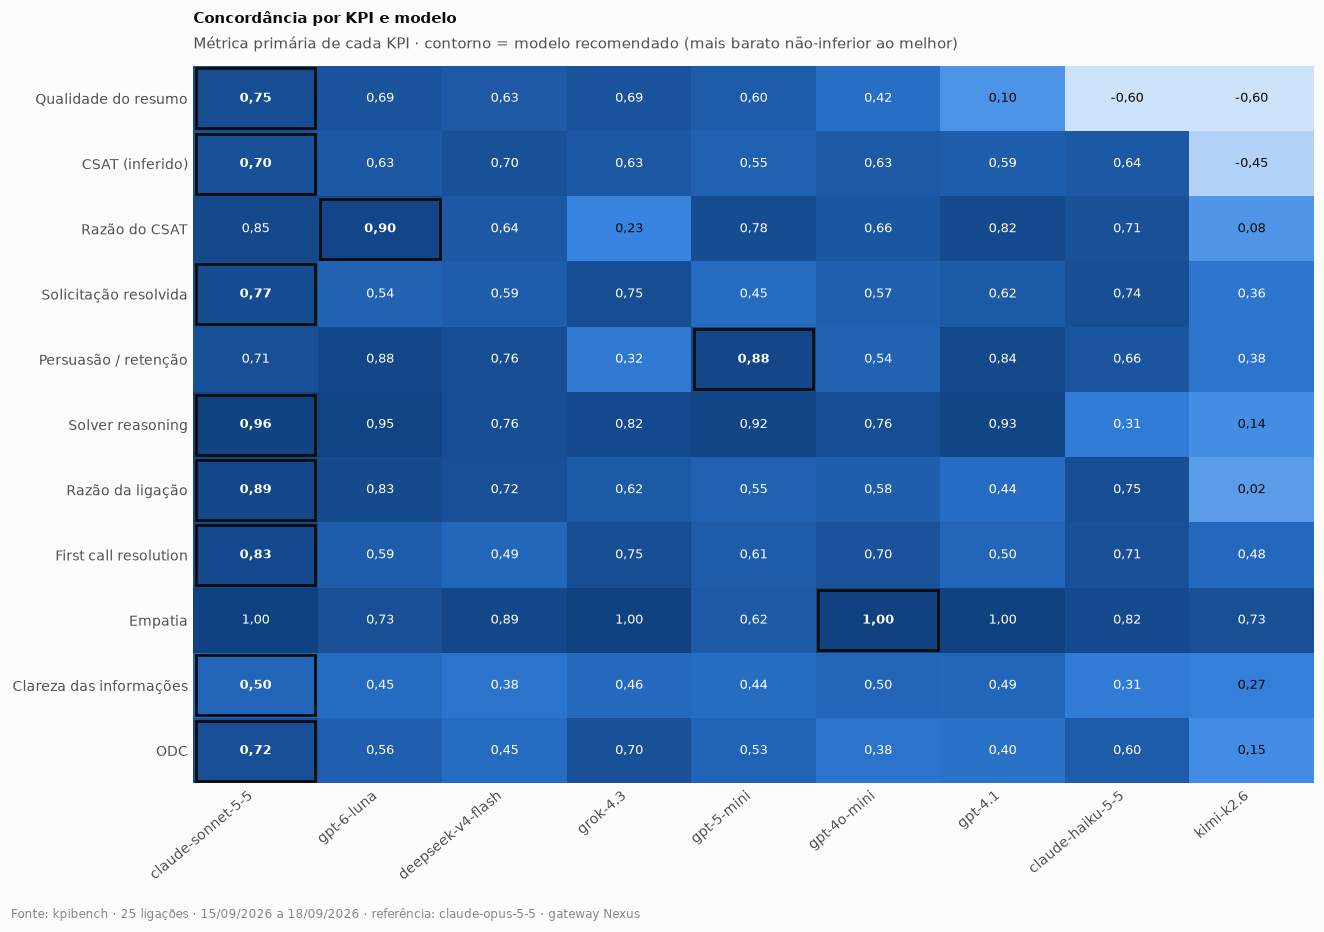

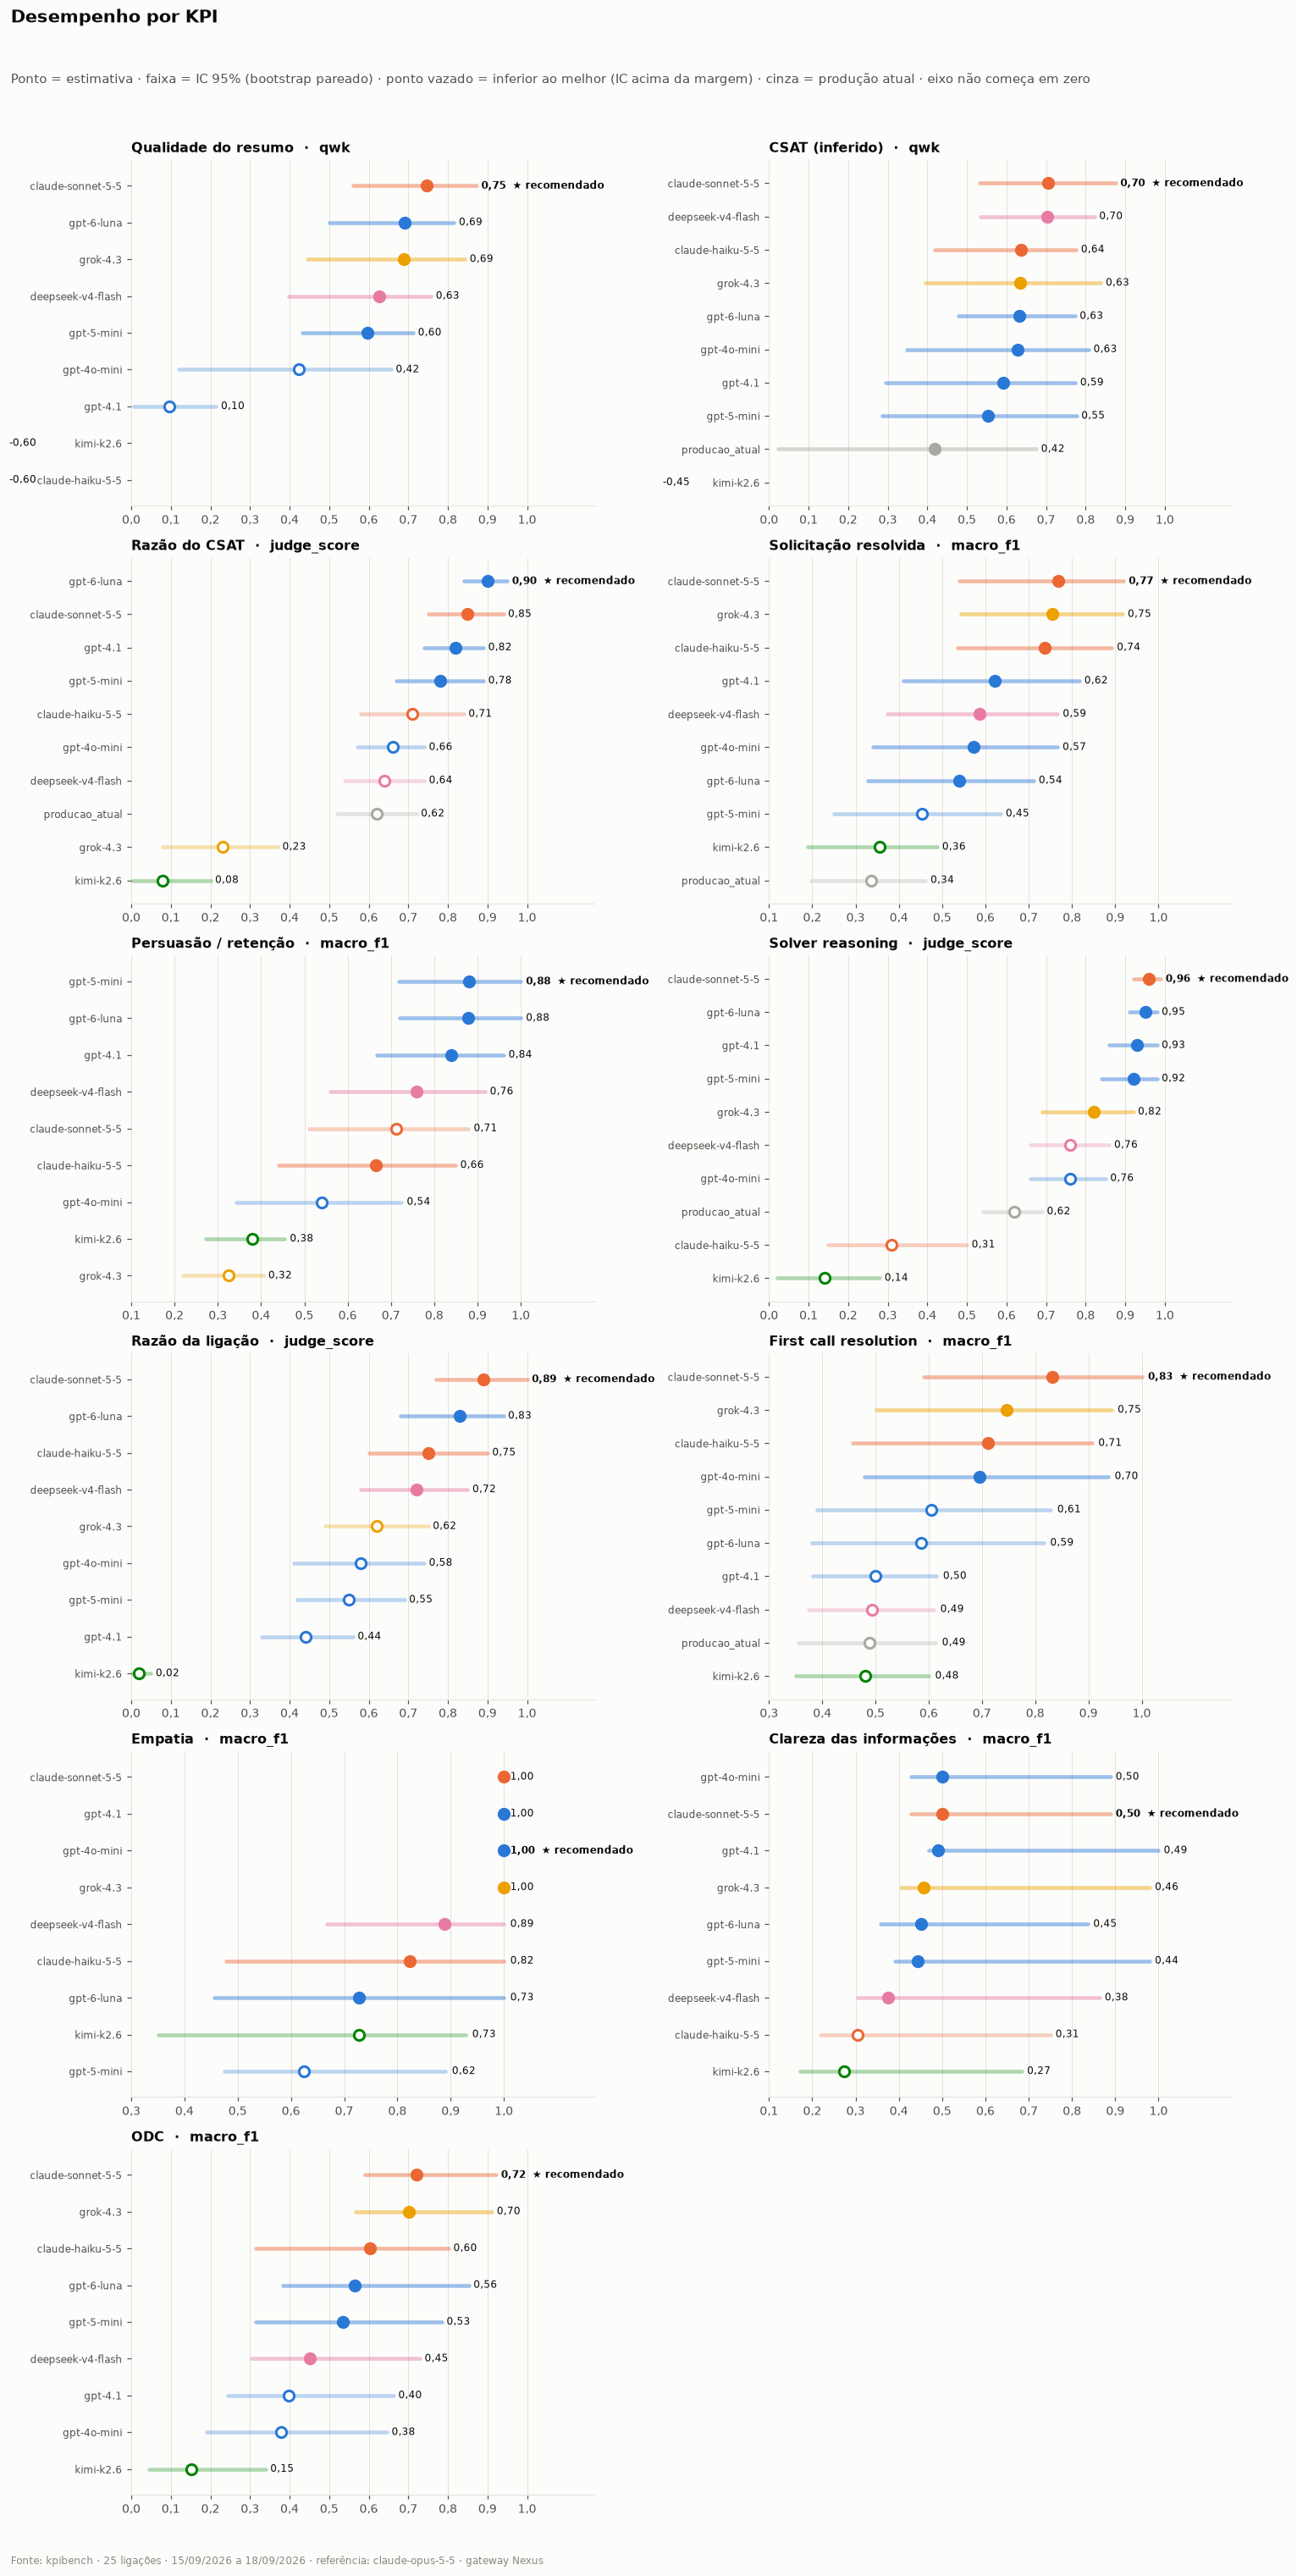

In [13]:
mostrar(charts.kpi_heatmap(res.metrics, res.routing, FOOTER))
mostrar(charts.kpi_small_multiples(res.metrics, res.routing, FOOTER))

### 7.6 Produção atual × modelo recomendado
Só nos KPIs em que o dado de produção tem domínio comparável. As regras de conversão aplicadas estão na tabela.

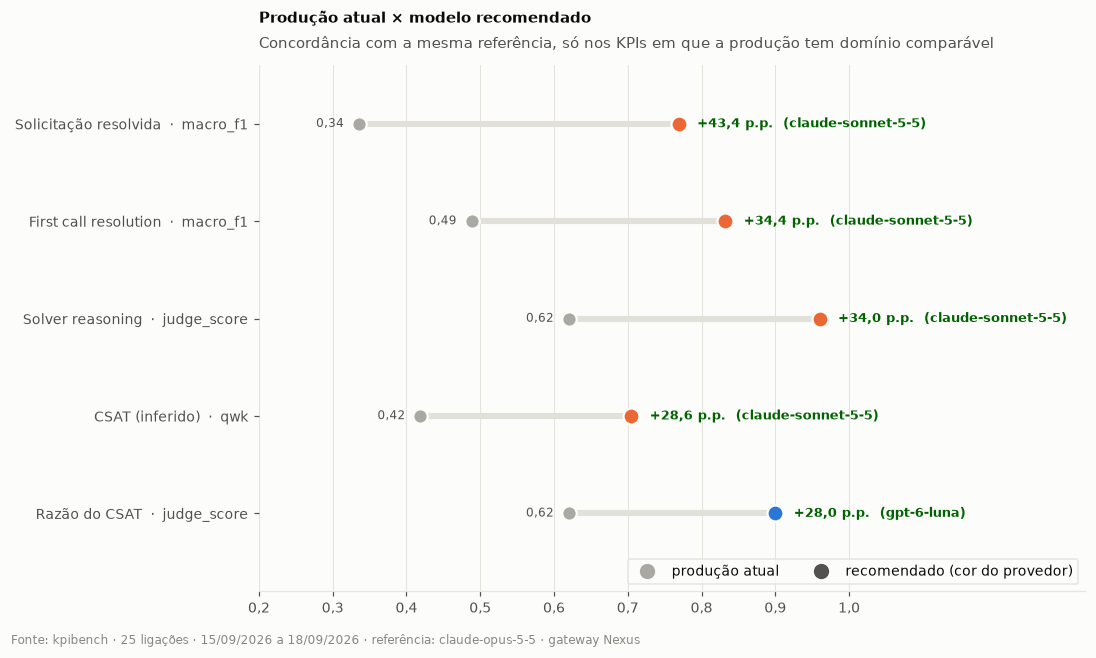

kpi,comparavel,regra
csat,True,"0–10 → 1–5 (≤2→1, ≤4→2, ≤6→3, ≤8→4, >8→5)"
solicitacao_resolvida,True,Sim/Não; produção não expressa 'parcial' (conta como erro quando a referência diz parcial)
first_call_resolution,True,Sim/Não; produção não expressa 'indeterminado'
razao_csat,True,"texto livre, avaliado pelo juiz contra a referência"
solver_reasoning,True,"texto livre, avaliado pelo juiz contra a referência"
empatia,False,produção Sim/Não × benchmark nota 1–5
clareza_informacoes,False,produção Sim/Não × benchmark nota 1–5
odc,False,produção Sim/Não × benchmark taxonomia de 7 códigos
razao_ligacao,False,produção texto livre × benchmark 8 rótulos
qualidade_resumo,False,não existe em produção


In [14]:
mostrar(charts.production_dumbbell(live.production_comparison(res), FOOTER))
display(resultado.production_notes.style.hide(axis="index"))

### 7.7 Roteamento recomendado por KPI
Cada KPI no modelo mais barato estatisticamente não-inferior ao melhor (`*` = preço estimado).

In [15]:
charts.style_routing(res.routing, placar)

KPI,Métrica,Recomendado,Concordância,IC 95%,US$ / 1.000 lig.,Melhor,Concordância do melhor,Economia vs melhor,Comparações inconclusivas
Qualidade do resumo,qwk,claude-sonnet-5-5 *,"0,746","[0,560; 0,872]","US$ 11,50",claude-sonnet-5-5,"0,746",0%,4
CSAT (inferido),qwk,claude-sonnet-5-5 *,"0,705","[0,531; 0,876]","US$ 3,03",claude-sonnet-5-5,"0,705",0%,8
Razão do CSAT,judge_score,gpt-6-luna *,"0,900","[0,840; 0,950]","US$ 0,075",gpt-6-luna,"0,900",0%,3
Solicitação resolvida,macro_f1,claude-sonnet-5-5 *,"0,769","[0,540; 0,919]","US$ 2,91",claude-sonnet-5-5,"0,769",0%,6
Persuasão / retenção,macro_f1,gpt-5-mini,"0,880","[0,718; 1,000]","US$ 0,46",gpt-5-mini,"0,880",0%,4
Solver reasoning,judge_score,claude-sonnet-5-5 *,"0,960","[0,920; 0,990]","US$ 2,93",claude-sonnet-5-5,"0,960",0%,4
Razão da ligação,judge_score,claude-sonnet-5-5 *,"0,890","[0,770; 1,000]","US$ 5,46",claude-sonnet-5-5,"0,890",0%,3
First call resolution,macro_f1,claude-sonnet-5-5 *,"0,832","[0,590; 1,000]","US$ 3,27",claude-sonnet-5-5,"0,832",0%,3
Empatia,macro_f1,gpt-4o-mini,"1,000","[1,000; 1,000]","US$ 0,10",claude-sonnet-5-5,"1,000",96%,3
Clareza das informações,macro_f1,claude-sonnet-5-5 *,"0,500","[0,428; 0,889]","US$ 2,95",claude-sonnet-5-5,"0,500",0%,6


Placar consolidado por modelo:

In [16]:
charts.style_scoreboard(placar)

Modelo,Provedor,Índice (0–100),KPIs não-inferiores,US$ / 1.000 lig.,Índice por US$,Latência p50,Latência p95,Respostas válidas,Preço estimado
claude-sonnet-5-5,Anthropic,"79,0",9 de 11,"US$ 44,16","1,8","1,5 s","3,4 s","100,0%",sim
gpt-6-luna,OpenAI,"70,5",1 de 11,"US$ 1,37","51,5","1,8 s","5,1 s","100,0%",sim
deepseek-v4-flash,DeepSeek,"63,7",0 de 11,"US$ 1,16","55,1","1,6 s","2,6 s","100,0%",sim
grok-4.3,xAI,"63,4",1 de 11,"US$ 8,19","7,7","8,2 s","15,4 s","100,0%",sim
gpt-5-mini,OpenAI,"63,1",1 de 11,"US$ 7,37","8,6","3,0 s","5,9 s","100,0%",não
gpt-4o-mini,OpenAI,"61,3",1 de 11,"US$ 1,45","42,3","1,6 s","2,6 s","100,0%",não
gpt-4.1,OpenAI,"61,2",1 de 11,"US$ 20,11","3,0","1,8 s","3,0 s","100,0%",não
claude-haiku-5-5,Anthropic,"56,8",0 de 11,"US$ 3,87","14,7","2,5 s","4,2 s","82,5%",sim
kimi-k2.6,Moonshot,"23,7",0 de 11,"US$ 55,06","0,4","7,1 s","13,5 s","35,3%",sim


**Por que um modelo pode aparecer com "Respostas válidas" abaixo de 100%:** o modelo participou da
rodada normalmente (não é o caso de `disponivel_no_nexus=False` da seção 2), mas em algumas chamadas a
resposta não veio no formato esperado (JSON fora do schema do KPI, campo ausente, texto extra ao redor
do JSON etc. — ver `kpibench/extraction/parser.py`, motivo `json_invalido`). Como `invalid_policy` está
em `"pessimistic"` (`config/benchmark.yaml`), essas respostas **não são descartadas**: contam como erro
máximo no cálculo da métrica daquele KPI, o que derruba tanto `Índice (0–100)` quanto a concordância do
modelo — ou seja, instabilidade de formatação pesa tanto quanto errar o conteúdo. Modelos que não
devolvem JSON de forma confiável (observado, por exemplo, em `kimi-k2.6` em rodadas anteriores) tendem a
ficar mal posicionados no placar por esse motivo, não necessariamente por "entender" pior a ligação —
vale inspecionar `taxa_resposta_valida` por KPI antes de descartar um modelo só pelo índice geral.

## 8. Inspeção de ligações

As ligações em que mais modelos discordaram da referência. Verde = igual à referência; vermelho = diferente;
KPIs de texto livre ficam sem cor (são avaliados pelo juiz, não por igualdade literal).
Para ver uma ligação específica: `charts.style_drilldown(live.call_drilldown(res, resultado.dataset, "<call_id>"))`.

In [17]:
for cid in live.most_divergent_calls(res, resultado.dataset, CASOS_PARA_INSPECIONAR):
    resumo = resultado.dataset.loc[resultado.dataset["call_id"] == cid, "resumo"].iloc[0]
    display(Markdown(f"**Ligação `{cid}`**"))
    display(charts.style_drilldown(live.call_drilldown(res, resultado.dataset, cid), resumo))

**Ligação `451e3dc9-cc5a-497a-ba2a-c4b201986633`**

,Referência,Produção,claude-haiku-5-5,claude-sonnet-5-5,deepseek-v4-flash,gpt-4.1,gpt-4o-mini,gpt-5-mini,gpt-6-luna,grok-4.3,kimi-k2.6
KPI,,,,,,,,,,,
Qualidade do resumo,4,—,⟂ inválido,5,5,5,4,5,5,5,⟂ inválido
CSAT (inferido),4,3,4,4,4,5,5,5,4,3,5
Razão do CSAT,"Satisfação positiva: contato ativo informativo sobre os sorteios do título, com postura cordial e encorajadora da atendente, sem problemas a resolver, encerrado com agradecimentos mútuos.","A satisfação de João parece ser moderada. Embora ele esteja ansioso há muitos anos, a atendente foi encorajadora e a conversa foi cordial, o que indica que ele pode ter saído um pouco mais animado, mas ainda permanece com uma expectativa alta e possivelmente alguma frustração acumulada.","A satisfação é positiva, sustentada pela postura cordial e encorajadora da atendente, que apresentou os benefícios do título e encerrou a ligação com agradecimentos. Não houve demanda a resolver nem problema relatado.","Contato ativo e cordial, em que a atendente explicou os benefícios do título e os sorteios e encorajou o cliente. Não há problema ou demanda pendente, e a conversa terminou com agradecimentos, indicando satisfação moderada a positiva.","A atendente informou benefícios e sorteios do título, gerando satisfação ao renovar a esperança do cliente, que aguardava há 40 anos.","O atendimento foi cordial e informativo, com a atendente explicando claramente os benefícios do título e demonstrando empatia ao encorajar o cliente, o que contribuiu para a satisfação no contato.","A satisfação de João parece estar relacionada à explicação clara dos benefícios do título e ao encorajamento da atendente, o que gerou uma interação positiva.","Atendimento informativo e encorajador: a atendente explicou benefícios e sorteios, motivou o cliente com novo número da sorte, encerrando de forma cordial, o que provavelmente gerou satisfação.","A conversa foi cordial e a atendente explicou os benefícios do título, incentivando o cliente com um novo número da sorte. Não há registro de problema, demora ou demanda não resolvida que indique insatisfação.",Resumo não traz elementos suficientes para explicar a satisfação.,Resumo não traz elementos suficientes para explicar a satisfação.
Solicitação resolvida,nao,nao,nao,nao,sim,nao,nao,sim,nao,nao,⟂ inválido
Persuasão / retenção,nao,—,sim,sim,sim,sim,sim,sim,sim,sim,⟂ inválido
Solver reasoning,Ligação ativa sem demanda do cliente: Rosana informou os benefícios do título (sorteios mensais de 10 mil e 100 mil reais e anual de 10 milhões em dezembro). Cliente ficou informado; nenhum protocolo ou próximo passo registrado.,"O problema relatado pelo cliente não foi resolvido, pois ele expressou insatisfação ao mencionar que está esperando há 40 anos por um sorteio, e não houve solução ou compromisso para resolver sua situação.",Resumo não descreve a resolução.,"Não havia demanda do cliente; a atendente ligou de forma ativa para informar os benefícios do título, explicando os sorteios mensais e o anual. O cliente ouviu e comentou sobre esperar um sorteio há 40 anos. Não há pendência nem próximo passo.",Atendente informou benefícios do título (ação). Cliente foi informado sobre sorteios (resultado). Próximo passo: cliente aguardar sorteios futuros.,"A atendente informou João sobre os benefícios e sorteios do título adquirido, esclarecendo valores e datas. Não houve solicitação de resolução de problema; a ligação foi apenas informativa, sem próximos passos definidos.",Resumo não descreve a resolução.,Atendente informou sobre benefícios e sorteios (mensais R$10.000 e R$100.000; anual R$10.000.000) -> cliente foi encorajado e conversa terminou cordialmente -> não há próximo passo informado.,"A atendente explicou os benefícios e sorteios do título, mas o resumo não descreve uma demanda ou resolução específica do cliente. Resumo não descreve a resolução.",Resumo não descreve a resolução.,Resumo não descreve a resolução.
Razão da ligação,informacoes_gerais,—,informacoes_gerais,info

**Ligação `45a9729a-6bec-495c-a53f-8c7d5eff0456`**

,Referência,Produção,claude-haiku-5-5,claude-sonnet-5-5,deepseek-v4-flash,gpt-4.1,gpt-4o-mini,gpt-5-mini,gpt-6-luna,grok-4.3,kimi-k2.6
KPI,,,,,,,,,,,
Qualidade do resumo,2,—,⟂ inválido,2,2,3,3,3,3,2,⟂ inválido
CSAT (inferido),4,3,3,3,5,3,3,4,4,4,⟂ inválido
Razão do CSAT,"Satisfação parcial: Paula entendeu que o cancelamento foi negado pela carência e que o crédito de R$ 2.232,13 sai a partir de 26/10 e agradeceu, mas a data exata do pedido de resgate não foi confirmada.","A satisfação do cliente parece ser neutra, pois embora tenha recebido orientações sobre a situação da agência, a questão do cancelamento e a incerteza sobre o resgate do crédito podem ter gerado frustração.","O pedido de cancelamento foi negado por estar em carência e a data exata do resgate não foi confirmada, deixando a demanda parcialmente resolvida. Isso tende a gerar insatisfação, mesmo com protocolo e liberação prevista do crédito.","O resumo não indica se a demanda foi resolvida: o cancelamento continua negado por causa da carência e a data exata do resgate não foi confirmada. Há apenas um agradecimento da cliente, sem sinal claro de satisfação ou insatisfação.","A demanda não foi resolvida, pois o cancelamento foi negado devido à carência, e a data de liberação do crédito não pôde ser confirmada, gerando insatisfação.","A satisfação foi gerada pela clareza nas explicações sobre o cancelamento e o crédito, além da postura prestativa do atendente, evidenciada pelo agradecimento de Paula ao final do atendimento.","A insatisfação decorre da negativa do pedido de cancelamento devido à carência, gerando frustração na cliente.","Atendimento esclareceu que cancelamento foi negado por carência e informou liberação do crédito em 26/10, mas não confirmou a data do resgate, gerando necessidade de novo contato e potencial insatisfação pelo problema não totalmente resolvido.","A satisfação tende a ser limitada porque o cancelamento foi negado devido à carência e a data exata do resgate não pôde ser confirmada, embora tenha sido informado o prazo para liberação do crédito.","A satisfação do cliente foi determinada pela ajuda recebida nos esclarecimentos sobre a negação do cancelamento devido à carência e a previsão de liberação do crédito, conforme o agradecimento de Paula.",Resumo não traz elementos suficientes para explicar a satisfação.
Solicitação resolvida,parcial,nao,parcial,parcial,nao,parcial,nao,sim,nao,parcial,⟂ inválido
Persuasão / retenção,nao,—,nao,nao,nao,nao,nao,nao,nao,nao,nao
Solver reasoning,"Atendente explicou que o cancelamento foi negado por estar na carência; informou crédito de R$ 2.232,13 previsto a partir de 26 de outubro, sem confirmar a data do pedido de resgate. Protocolo 64751858.","O problema não foi resolvido porque o cancelamento foi negado devido à carência da agência, e não há confirmação da data exata do pedido de resgate do crédito.",⟂ inválido,"Atendente verificou o caso, identificou que o cancelamento foi negado porque a cliente estava na carência. Informou crédito de R$ 2.232,13 previsto a partir de 26 de outubro, mas não confirmou a data exata do resgate. Protocolo 64751858 gerado.","Atendente explicou que cancelamento foi negado por carência. Crédito de R$ 2.232,13 previsto para 26/10. Protocolo 64751858. Próximo passo: aguardar liberação do crédito.","Atendente explicou que o cancelamento foi negado devido à carência. Informou que o crédito de R$ 2.232,13 será liberado a partir de 26/10. Não foi possível confirmar a data exata do pedido de resgate. Protocolo: 64751858.","Atendente explicou que o cancelamento foi negado devido à carência. O crédito de R$ 2.232,13 será liberado em 26 de outubro, mas a data do resgate não foi confirmada.","Atendente confirmou identidade, registrou protocolo 64751858 e explicou que cancelamento foi negado por carência; crédito de R$ 2.232,13 será liberado a partir de 26 de outubro; não foi possível confirmar data do pedido de resgate; Francisco avaliará atendimento.","O atendente esclareceu que 

**Ligação `25f7c3ae-acd2-48e6-ac7a-9095b92b1d08`**

,Referência,Produção,claude-haiku-5-5,claude-sonnet-5-5,deepseek-v4-flash,gpt-4.1,gpt-4o-mini,gpt-5-mini,gpt-6-luna,grok-4.3,kimi-k2.6
KPI,,,,,,,,,,,
Qualidade do resumo,2,—,⟂ inválido,2,2,5,3,3,3,2,⟂ inválido
CSAT (inferido),4,3,3,4,5,4,3,5,4,4,⟂ inválido
Razão do CSAT,"Paula obteve os esclarecimentos principais, a negativa do cancelamento por carência e o crédito do resgate de R$ 2.232,13 a partir de 26/10, e agradeceu. A data da solicitação do resgate ficou sem confirmação.","A satisfação do cliente parece ser moderada, pois houve um esclarecimento sobre a situação, mas também há uma preocupação com o cancelamento e a carência, indicando que a situação não foi totalmente satisfatória. O cliente pode ainda se sentir inseguro quanto ao processo de resgate.","Insatisfação motivada pela negativa do cancelamento por causa da carência e pela impossibilidade de verificar quando o resgate de R$ 2.232,13 foi solicitado, deixando a dúvida da cliente sem resolução completa.","Atendimento esclareceu a situação (cancelamento negado por carência e resgate de R$ 2.232,13 previsto a partir de 26/10), mas não foi possível confirmar quando o resgate foi solicitado, deixando uma lacuna. A cliente agradeceu, sugerindo satisfação moderada.","A demanda foi esclarecida, com informações sobre carência e resgate, gerando satisfação.","A satisfação foi determinada pela clareza das informações prestadas sobre o cancelamento e o resgate, além da postura cordial do atendente, embora não tenha sido possível informar a data exata da solicitação do resgate.","A satisfação da cliente pode ter sido impactada pela falta de clareza sobre o cancelamento e o resgate, gerando incerteza e insatisfação.",Gerou satisfação por esclarecer que o cancelamento foi negado devido à carência e informar a data prevista do resgate; houve limitação ao não conseguir verificar quando o resgate foi solicitado.,"A satisfação tende a ser influenciada pelo esclarecimento sobre a negativa do cancelamento por carência e pela previsão de crédito do resgate, embora a data da solicitação não tenha sido confirmada.",Resumo não traz elementos suficientes para explicar a satisfação.,Resumo não traz elementos suficientes para explicar a satisfação.
Solicitação resolvida,parcial,nao,parcial,parcial,parcial,sim,nao,sim,sim,parcial,sim
Persuasão / retenção,nao,—,nao,nao,nao,nao,nao,nao,nao,nao,nao
Solver reasoning,"Francisco solicitou CPF e nome da cliente, confirmou o protocolo 64751858 e informou que o cancelamento foi negado pela carência. O resgate de R$ 2.232,13 será creditado a partir de 26 de outubro; não foi possível verificar a data da solicitação.",O problema não foi resolvido porque o cliente não conseguiu cancelar o título devido à carência e não houve confirmação sobre a data de solicitação do resgate.,⟂ inválido,"Francisco pediu CPF e nome da cliente, confirmou o protocolo 64751858 e verificou o histórico: o cancelamento no início da vigência foi negado por carência. Resultado: resgate de R$ 2.232,13 previsto para crédito a partir de 26 de outubro; não foi possível verificar quando foi solicitado.","Francisco informou que o cancelamento foi negado por carência. O resgate de R$ 2.232,13 está previsto para 26/10. Protocolo 64751858.","Atendente confirmou protocolo, explicou que cancelamento foi negado devido à carência e informou previsão de resgate de R$ 2.232,13 a partir de 26/10. Não foi possível informar quando o resgate foi solicitado.","Atendente confirmou que o cancelamento foi negado devido à carência. Informou que o resgate de R$ 2.232,13 será creditado a partir de 26 de outubro.","Atendente confirmou CPF, nome e protocolo 64751858 -> informou que cancelamento foi negado por carência; resgate de R$ 2.232,13 será creditado a partir de 26/10; não foi possível verificar data da solicitação; sem próximo passo informado.","Francisco confirmou os dados e explicou que o cancelamento foi negado devido à carência. Informou que o resgate de R$ 2.232,13 será creditado a partir de 26 

## 9. Exportar painéis

In [18]:
paineis = {
    "01_resumo": charts.scorecards(placar, res.routing, N, FOOTER),
    "02_ranking": charts.leaderboard(placar, FOOTER, REFERENCIA),
    "03_concordancia_custo": charts.quality_vs_cost(placar, FOOTER),
    "04_custo": charts.cost_bars(placar, FOOTER),
    "05_latencia": charts.latency_chart(placar, FOOTER, sla_s=SLA_LATENCIA_S),
    "06_confiabilidade": charts.reliability_bars(placar, FOOTER),
    "07_heatmap_kpi": charts.kpi_heatmap(res.metrics, res.routing, FOOTER),
    "08_kpis_ic": charts.kpi_small_multiples(res.metrics, res.routing, FOOTER),
    "09_producao": charts.production_dumbbell(live.production_comparison(res), FOOTER),
}
destino = resultado.out_dir / "paineis"
destino.mkdir(exist_ok=True)
for nome, fig in paineis.items():
    if fig is not None:
        fig.savefig(destino / f"{nome}.png")
        plt.close(fig)
placar.to_csv(resultado.out_dir / "placar_modelos.csv", index=False)
print(f"Painéis e placar salvos em: {destino.parent}")
print(f"Relatório completo: {resultado.run_dir / 'report.md'}")

Painéis e placar salvos em: /home/ab1344549/PSO/DataOcean.MLPSO/llm_bench/rev2/kpillmbenchmark/outputs/teste_ligacoes_20261111_160256
Relatório completo: /home/ab1344549/PSO/DataOcean.MLPSO/llm_bench/rev2/kpillmbenchmark/outputs/teste_ligacoes_20261111_160256/benchmark_20261111_160345/report.md


## Limitações

- **Concordância ≠ acerto.** Com referência por modelo, um candidato da mesma família da referência tende a
  concordar mais com ela. Para decisão final, use rótulos auditados (`REFERENCIA = "arquivo:..."`) numa amostra.
- **Preços estimados** (marcados em `config/models.yaml`) não incluem eventual markup do Nexus.
- **Amostra:** comparações "inconclusivas" pedem mais ligações, não uma decisão.
- **Latência** medida do notebook até o Nexus; inclui rede e fila do gateway.

## 10. Leitura crítica (o que falta para este estudo virar decisão)

Visão de analista sênior de qualidade de ligações + cientista de dados sobre o que existe hoje e o que
é indispensável antes de usar este notebook para **substituir ou redirecionar** o modelo em produção:

1. **A referência é um juiz, não a verdade.** Hoje "acerto" = concordância com `REFERENCIA`
   (`claude-opus-5-5`), um modelo da mesma família de vários candidatos. Isso infla a nota de modelos
   "aparentados" e penaliza modelos estruturalmente diferentes que podem estar certos. **Sem uma amostra
   com rótulo humano auditado (dupla avaliação + desempate) para calcular acordo inter-avaliador
   (ex.: Krippendorff's α ou Cohen's κ ponderado) entre referência e humano, não há como saber se a
   referência é boa o suficiente para ancorar a decisão.**
2. **Tamanho de amostra incompatível com a decisão.** `NUM_CALLS = 10` (e mesmo "algumas centenas",
   como o próprio notebook recomenda) é pouco para KPIs raros ou com baixa prevalência (ex.: ODC,
   reclamação). É preciso um cálculo de poder estatístico por KPI (efeito mínimo detectável, variância
   observada no bootstrap) antes de fixar o N de uma rodada de decisão — não só olhar o rótulo
   "inconclusivo" depois do fato.
3. **5 KPIs têm domínio incompatível com produção** (`empatia`, `clareza_informacoes`, `odc`,
   `razao_ligacao`, `qualidade_resumo` — ver seção 7.6/`production_notes`). Isso significa que, para boa
   parte do escopo, **não existe baseline real para comparar ganho** — o estudo mede o modelo novo contra
   si mesmo (via referência), não contra o que já roda hoje. Sem um mapeamento de domínio auditado
   (ou uma rodada piloto em que humanos pontuam produção no mesmo domínio do benchmark), a alegação de
   "ganho sobre produção" não é sustentável para esses KPIs.
4. **Nenhuma análise de erro por segmento.** O placar agrega tudo: tipo de ligação, duração, canal,
   sentimento do cliente, horário. Um modelo pode "ganhar na média" e ser sistematicamente pior em
   ligações de reclamação ou em ligações longas — exatamente onde o custo de errar é maior. Faltam
   cortes por subgrupo (pelo menos por `razao_ligacao`/tipo de caso e por faixa de duração) antes de
   declarar um vencedor único.
5. **Viés de auto-preferência (self-preference bias) não testado.** Está bem documentado na literatura
   de "LLM-as-judge" que um modelo tende a favorecer saídas estilisticamente parecidas com as suas
   (e é por isso que modelos da mesma família tendem a "concordar mais"). Com `JUIZ = gpt-6-luna` e
   referência de outra família, já há uma mitigação parcial, mas não há teste explícito de
   sensibilidade (ex.: trocar o juiz/referência e ver se o ranking muda).
6. **Robustez do prompt não avaliada.** Um único prompt por KPI (`prompts/kpis/*`) é testado. Não se
   sabe se o ranking entre modelos se mantém com pequenas variações de redação, ordem dos campos ou
   paráfrases do mesmo pedido — um modelo pode estar perdendo por ser mais sensível a prompt, não por
   entender pior a ligação.
7. **Estabilidade temporal/drift não medida.** Uma única janela (`START_DATE`–`END_DATE`) e uma única
   rodada. Modelos via API mudam de versão sem aviso (o próprio bug de `temperature` corrigido neste
   projeto é um exemplo de quebra silenciosa). É preciso reexecução periódica (ex.: mensal) com o mesmo
   conjunto de ligações para detectar regressão de qualidade ou de custo antes que vire incidente em
   produção.
8. **Custo de erro não é uniforme entre KPIs.** O índice geral pondera KPIs por `PESOS_KPI`, mas o
   impacto de negócio de errar `first_call_resolution` ou `odc` (afeta métrica regulatória/CSAT em
   escala) não é o mesmo que errar `clareza_informacoes`. Falta uma matriz de custo de erro
   (falso positivo × falso negativo por KPI) definida com a área de negócio, não só um peso numérico
   arbitrário.
9. **Confiabilidade operacional fora de escopo.** O notebook mede latência (p50/p95) numa rodada
   pequena e sequencial/paralela limitada (`MAX_WORKERS`). Não há teste de carga real (milhares de
   chamadas simultâneas, retries, timeouts, rate limit do Nexus) nem SLA de disponibilidade do provedor —
   crítico para um serviço de produção que depende de um gateway de terceiros.
10. **Segurança e dados sensíveis não tratados aqui.** Resumos e transcrições de ligação podem conter
    dados pessoais (LGPD). Não há, neste notebook, avaliação de mascaramento/anonimização antes de
    enviar o conteúdo a provedores externos via Nexus, nem registro de qual conteúdo foi enviado a quem
    — necessário para qualquer auditoria de privacidade antes de produção.
11. **Sem plano de rollout.** Mesmo com um vencedor estatisticamente claro, falta o desenho do caminho
    até produção: shadow mode (rodar em paralelo sem afetar decisão), canário (% pequeno de tráfego),
    critério objetivo de rollback, e monitoramento contínuo do índice em produção — não apenas a
    comparação pontual deste notebook.

**Conclusão:** este notebook é uma ferramenta sólida de **triagem** (reduz o espaço de modelos
candidatos e estima custo/latência rapidamente), mas **não substitui** uma validação com rótulo humano
auditado, análise de subgrupo, teste de robustez de prompt e um plano de rollout controlado. Tratar o
"Índice (0–100)" desta rodada como veredito final seria um erro metodológico.
